1. Loading Dataset and Tokenizer...


config.json:   0%|          | 0.00/654 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/73.0 [00:00<?, ?B/s]


2. Analyzing Structural Integrity...
Rows missing '####' delimiter: 0
Average calculator annotations per answer: 3.17

3. Calculating Token Length Distributions...

Token Length Percentiles:
       prompt_tokens  completion_tokens  total_tokens
count    7473.000000        7473.000000   7473.000000
mean       90.311120         105.317677    195.628797
std        21.030058          43.776304     57.637180
min        44.000000          27.000000     89.000000
50%        86.000000          96.000000    185.000000
90%       119.000000         164.000000    275.000000
95%       130.000000         191.000000    306.000000
99%       157.000000         237.280000    365.000000
max       242.000000         366.000000    496.000000

4. Plotting Distributions...


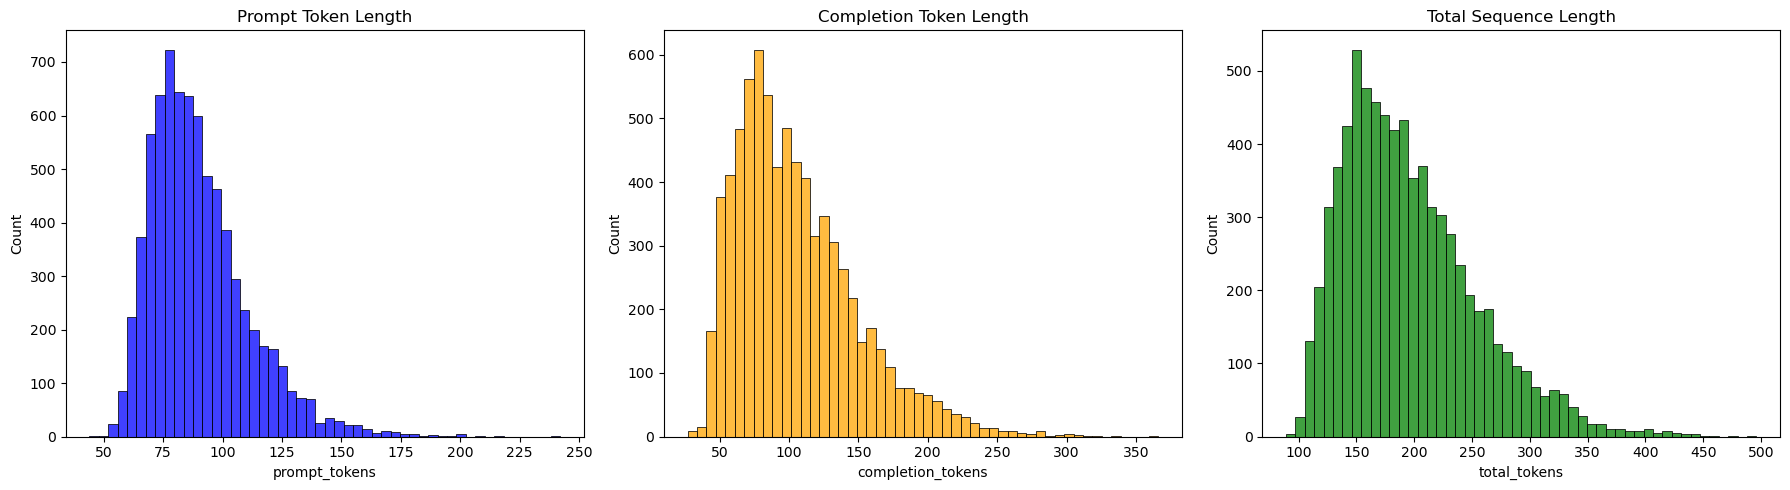


5. Vocabulary Frequency Analysis (Router Prep)...


C:\Users\ozgur\AppData\Local\Temp\ipykernel_14868\2844294032.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words), palette="viridis")


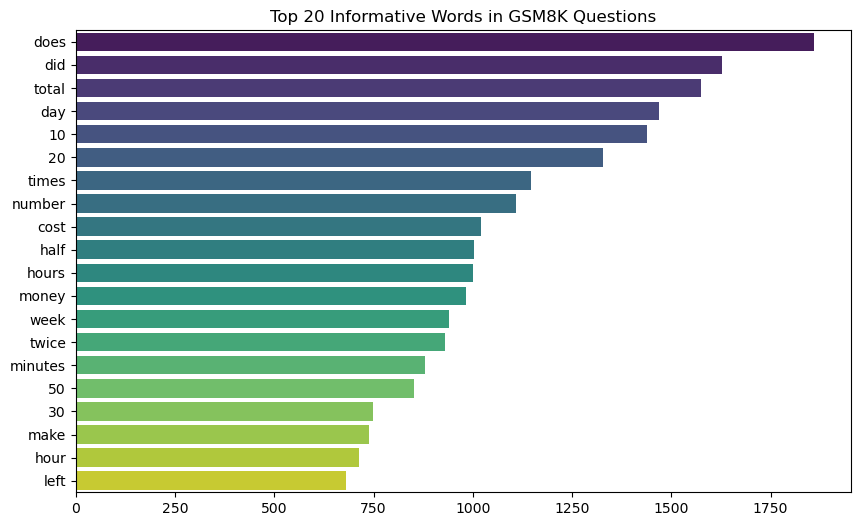

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import AutoTokenizer
from sklearn.feature_extraction.text import CountVectorizer


def run_gsm8k_eda(model_id: str = "NousResearch/Meta-Llama-3-8B-Instruct"):
    print("1. Loading Dataset and Tokenizer...")
    dataset = load_dataset("openai/gsm8k", "main")
    train_df = dataset["train"].to_pandas()

    # Load the Llama 3 tokenizer to get accurate subword counts
    tokenizer = AutoTokenizer.from_pretrained(model_id)

    print("\n2. Analyzing Structural Integrity...")
    # Verify the #### delimiter exists in every answer
    missing_delimiter = train_df[~train_df["answer"].str.contains("####")]
    print(f"Rows missing '####' delimiter: {len(missing_delimiter)}")

    # Count frequency of <<equation=answer>> annotations
    train_df["calc_annotations_count"] = train_df["answer"].str.count(r"<<.*?>>")
    print(
        f"Average calculator annotations per answer: {train_df['calc_annotations_count'].mean():.2f}"
    )

    print("\n3. Calculating Token Length Distributions...")

    # Apply Llama 3 Chat Template to calculate true sequence lengths
    def calculate_lengths(row):
        messages = [
            {
                "role": "system",
                "content": "You are a mathematical reasoning assistant. Solve the problem step-by-step and provide the final answer after ####.",
            },
            {"role": "user", "content": row["question"]},
            {"role": "assistant", "content": row["answer"]},
        ]
        # Format string without tokenizing to see raw text
        formatted_string = tokenizer.apply_chat_template(messages, tokenize=False)

        prompt_only = messages[:2]
        formatted_prompt = tokenizer.apply_chat_template(prompt_only, tokenize=False)

        # Tokenize to get lengths
        total_tokens = len(tokenizer.encode(formatted_string))
        prompt_tokens = len(tokenizer.encode(formatted_prompt))
        completion_tokens = total_tokens - prompt_tokens

        return pd.Series([prompt_tokens, completion_tokens, total_tokens])

    train_df[["prompt_tokens", "completion_tokens", "total_tokens"]] = train_df.apply(
        calculate_lengths, axis=1
    )

    # Output percentiles to dictate max_length parameter
    print("\nToken Length Percentiles:")
    print(
        train_df[["prompt_tokens", "completion_tokens", "total_tokens"]].describe(
            percentiles=[0.50, 0.90, 0.95, 0.99]
        )
    )

    print("\n4. Plotting Distributions...")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.histplot(
        train_df["prompt_tokens"], bins=50, ax=axes[0], color="blue"
    ).set_title("Prompt Token Length")
    sns.histplot(
        train_df["completion_tokens"], bins=50, ax=axes[1], color="orange"
    ).set_title("Completion Token Length")
    sns.histplot(
        train_df["total_tokens"], bins=50, ax=axes[2], color="green"
    ).set_title("Total Sequence Length")
    plt.tight_layout()
    plt.show()

    print("\n5. Vocabulary Frequency Analysis (Router Prep)...")
    # Extract top 20 words (excluding English stop words) to verify mathematical signal
    vectorizer = CountVectorizer(stop_words="english", max_features=20)
    word_counts = vectorizer.fit_transform(train_df["question"]).sum(axis=0)
    words_freq = [
        (word, word_counts[0, idx]) for word, idx in vectorizer.vocabulary_.items()
    ]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)

    words, counts = zip(*words_freq)
    plt.figure(figsize=(10, 6))
    sns.barplot(x=list(counts), y=list(words), palette="viridis")
    plt.title("Top 20 Informative Words in GSM8K Questions")
    plt.show()


if __name__ == "__main__":
    # Note: Ensure you have run `huggingface-cli login` to access Llama 3 tokenizer
    run_gsm8k_eda()
